## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet("ff_market_daily.parquet")
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

c:\Users\Sebastien\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


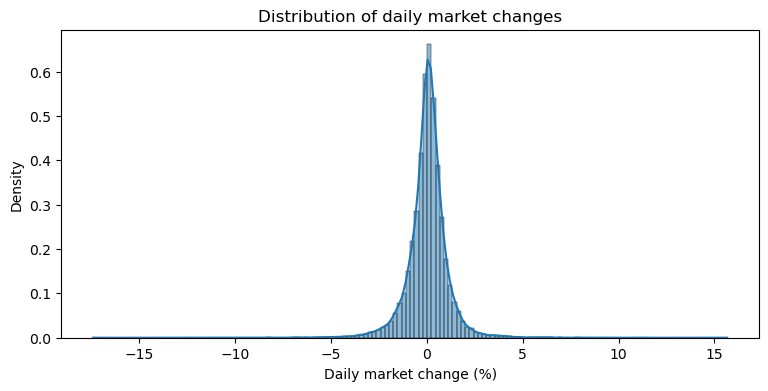

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

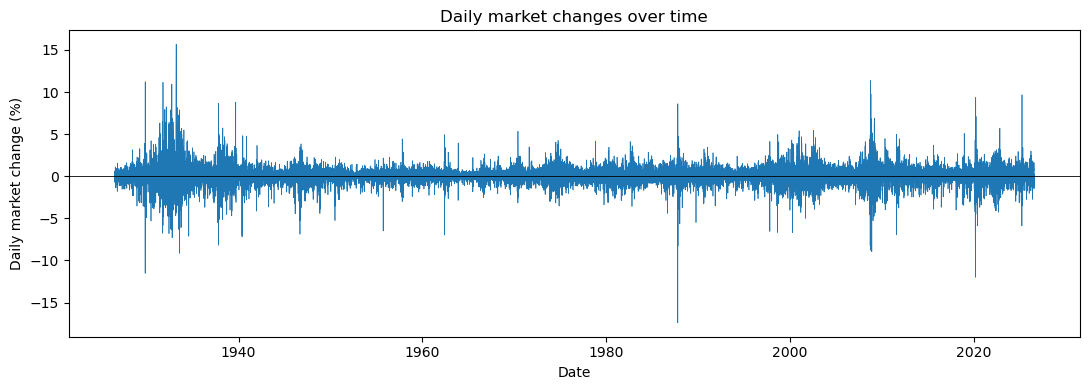

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
df['ret_today'] = df['market_return_pct']
df['ret_tomorrow'] = df['market_return_pct'].shift(-1)

# Drop the last row, which has no "next day"
pairs = df.dropna(subset=['ret_tomorrow']).copy()

# Two states: Up (> 0) and Down (<= 0, including flat)
pairs['state_today'] = np.where(pairs['ret_today'] > 0, 'Up', 'Down')
pairs['state_tomorrow'] = np.where(pairs['ret_tomorrow'] > 0, 'Up', 'Down')

# Joint PMF: P(today, tomorrow)
joint = pd.crosstab(pairs['state_today'], pairs['state_tomorrow'], normalize='all')

# Marginals
marg_t = joint.sum(axis=1)     # P(today)
marg_tp1 = joint.sum(axis=0)   # P(tomorrow)

# Conditional PMF: P(tomorrow | today), each row sums to 1
cond = joint.div(marg_t, axis=0)

print("Joint PMF:\n", joint.round(4), "\n")
print("Marginal PMF, today:\n", marg_t.round(4), "\n")
print("Marginal PMF, tomorrow:\n", marg_tp1.round(4), "\n")
print("Conditional PMF, P(tomorrow | today):\n", cond.round(4))

Joint PMF:
 state_tomorrow    Down      Up
state_today                   
Down            0.2247  0.2281
Up              0.2281  0.3190 

Marginal PMF, today:
 state_today
Down    0.4529
Up      0.5471
dtype: float64 

Marginal PMF, tomorrow:
 state_tomorrow
Down    0.4529
Up      0.5471
dtype: float64 

Conditional PMF, P(tomorrow | today):
 state_tomorrow    Down      Up
state_today                   
Down            0.4962  0.5038
Up              0.4170  0.5830


Up transitions are more common than down transitions

You are more likely to transition from a Down day to an Up day

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['ret_today'] = df['market_return_pct']
df['ret_tomorrow'] = df['market_return_pct'].shift(-1)


df['bin_today'] = pd.cut(df['ret_today'], bins=bins, labels=labels, ordered=True)
df['bin_tomorrow'] = df['bin_today'].shift(-1)
pairs5 = df.dropna(subset=['ret_tomorrow']).copy()

# Counts per bin
counts = pairs5['bin_today'].value_counts().reindex(labels)
print("Days per bin:\n", counts, "\n")
print("Most common:", counts.idxmax(), "| Least common:", counts.idxmin(), "\n")

# Joint PMF and marginals 
joint5 = pd.crosstab(pairs5['bin_today'], pairs5['bin_tomorrow'], normalize='all').reindex(index=labels, columns=labels)
marg_t5 = joint5.sum(axis=1)     # P(today)
marg_tp15 = joint5.sum(axis=0)   # P(tomorrow)

print("Joint PMF:\n", joint5.round(4), "\n")
print("Marginal, today:\n", marg_t5.round(4), "\n")
print("Marginal, tomorrow:\n", marg_tp15.round(4), "\n")

# Most likely transitions (top 5 cells of the joint PMF)
top_joint = joint5.stack().sort_values(ascending=False).head(5)
print("Most likely transitions (today -> tomorrow):\n", top_joint.round(4), "\n")

# Conditional PMF: P(tomorrow | today), rows sum to 1
cond5 = joint5.div(marg_t5, axis=0)
print("Conditional PMF:\n", cond5.round(4), "\n")

# Two most likely next states for each current state
top2 = cond5.apply(lambda row: row.nlargest(2).index.tolist(), axis=1)
print("Two most likely next states:\n", top2, "\n")

# How far is each row from uniform (0.2 everywhere)?
# Total variation distance: 0 = exactly uniform, larger = more predictable
tv_dist = (cond5 - 0.2).abs().sum(axis=1) / 2
print("Distance from uniform (total variation):\n", tv_dist.round(4), "\n")

#  Tomorrow's return, grouped by today's state 
summary = pairs5.groupby('bin_today', observed=True)['ret_tomorrow'].describe().reindex(labels)
print("Tomorrow's market_return_pct by today's state:\n")
print(summary.round(3))

Days per bin:
 bin_today
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9784
Large gain    2859
Name: count, dtype: int64 

Most common: Small gain | Least common: Large loss 

Joint PMF:
 bin_tomorrow  Large loss  Small loss  Near zero  Small gain  Large gain
bin_today                                                              
Large loss        0.0213      0.0272     0.0091      0.0278      0.0195
Small loss        0.0354      0.0886     0.0342      0.0978      0.0274
Near zero         0.0093      0.0420     0.0210      0.0493      0.0093
Small gain        0.0250      0.1001     0.0550      0.1594      0.0326
Large gain        0.0138      0.0255     0.0116      0.0378      0.0199 

Marginal, today:
 bin_today
Large loss    0.1049
Small loss    0.2834
Near zero     0.1309
Small gain    0.3721
Large gain    0.1087
dtype: float64 

Marginal, tomorrow:
 bin_tomorrow
Large loss    0.1049
Small loss    0.2834
Near zero     0.1308
Small gain    0.3721
Large gain   

It's relatively easy/difficult to predict the next state because no matter what state you start in, the next 2 most likely states are going to be small gain and small loss.

The min value is smallest for the large loss state and largest at the near 0 state. The max value is smallest at the near 0 state and largest at the large gain state.
The states that have the largest std deviation for tommorow's percent returns is the large loss state.
Interestingly enough, large loss has the 2nd highest 75% quartile range for market return, only less than large gain. This emphasizes the point that it has the largest std. deviation out of the other states.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

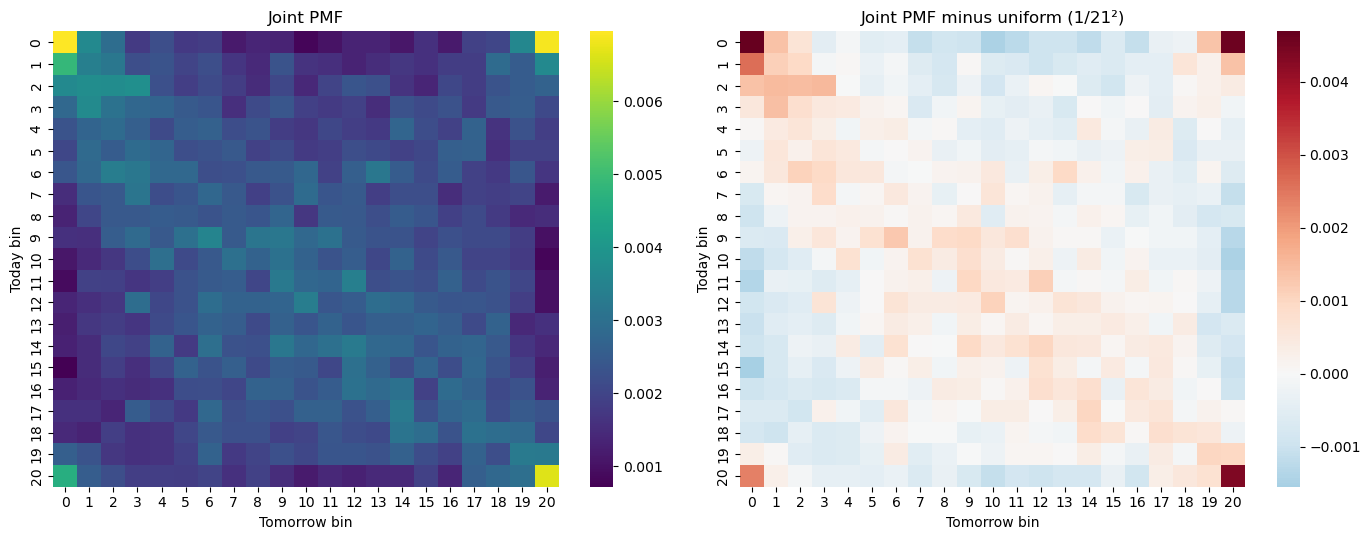

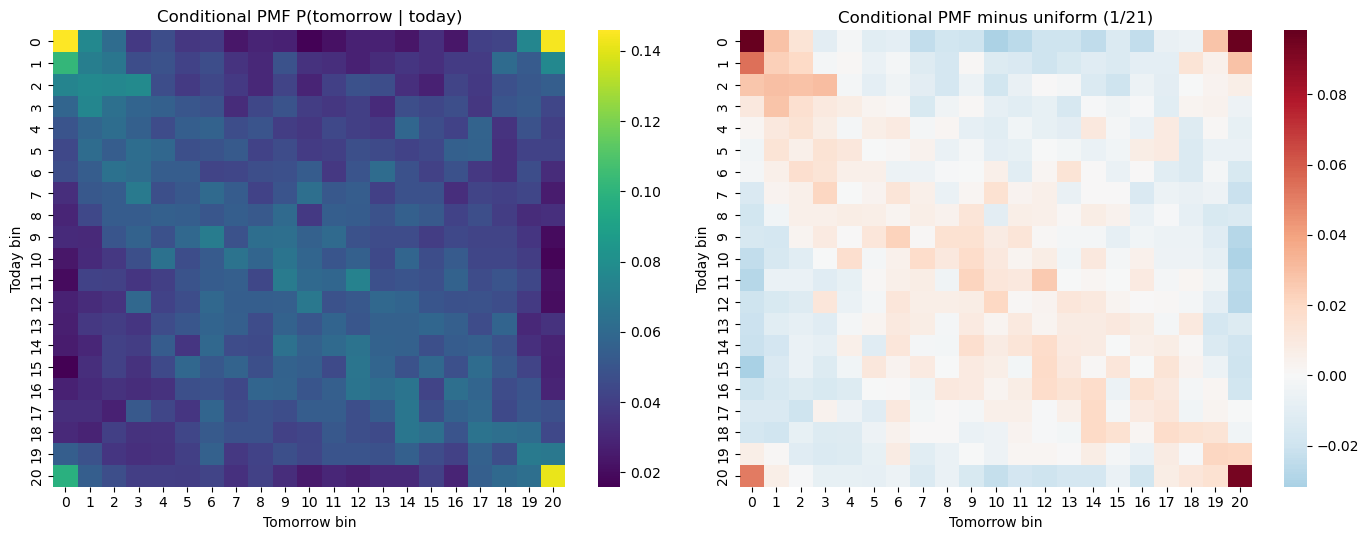

           min   mean    max    std
y_today                            
0       -17.41 -0.014  11.22  2.140
1        -7.36 -0.077   6.36  1.286
2        -8.79 -0.097  11.36  1.228
3        -8.28 -0.059   6.16  1.050
4        -6.89 -0.024   4.56  0.989
5       -11.23 -0.023   6.37  1.025
6        -3.94 -0.030   7.37  0.930
7        -3.40 -0.014   4.76  0.836
8        -6.00  0.026   5.49  0.853
9        -8.19 -0.013   3.60  0.812
10       -7.30  0.035   4.69  0.805
11       -8.25  0.092   7.88  0.792
12       -6.82  0.057   5.66  0.784
13       -5.12  0.088   4.16  0.817
14       -6.49  0.091   5.70  0.831
15       -6.99  0.126   8.67  0.790
16       -7.13  0.126   4.84  0.827
17       -6.30  0.130   8.60  0.960
18       -8.96  0.175   4.38  0.901
19       -4.93  0.133   6.04  1.100
20      -12.00  0.195  15.67  1.703


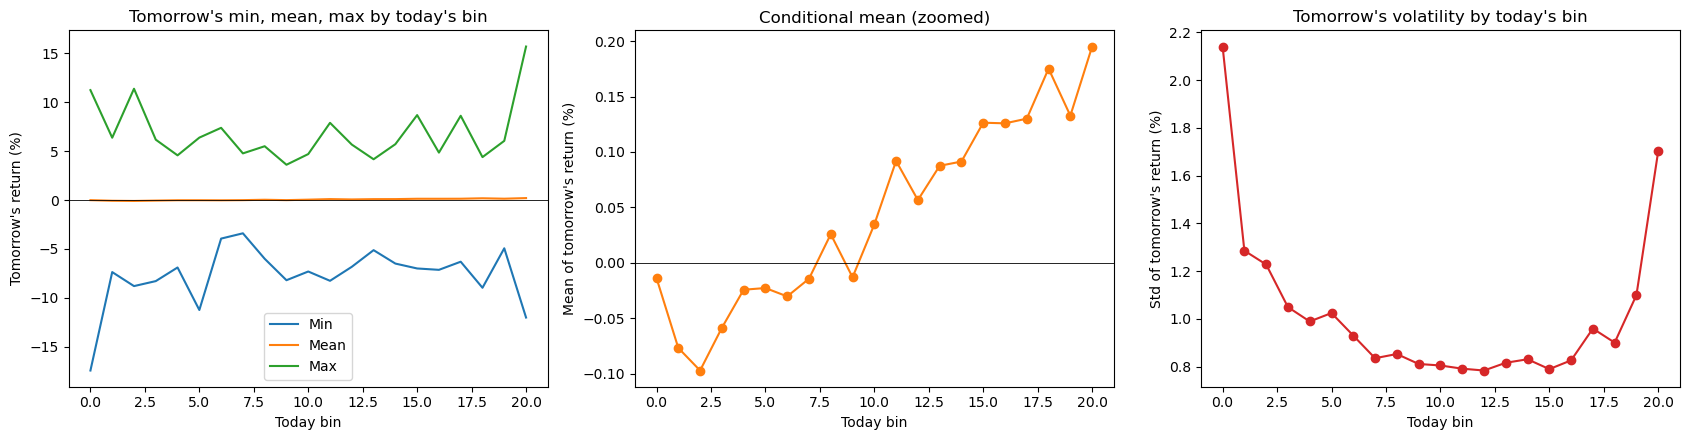

Largest deviation of any conditional probability from 1/21: 0.0982  (uniform value = 0.0476)
Conditional means range from -0.097% to 0.195%, vs. an unconditional std of 1.077%


In [9]:
n_bins = 21
df['ret_today'] = df['market_return_pct']
df['ret_tomorrow'] = df['market_return_pct'].shift(-1)

# 21 equal-probability bins (0 = worst days, 20 = best days)
df['y_today'] = pd.qcut(df['ret_today'], q=n_bins, labels=False)
df['y_tomorrow'] = df['y_today'].shift(-1)

# Drop the last row, which has no "next day"
pairs21 = df.dropna(subset=['y_tomorrow']).copy()
pairs21['y_tomorrow'] = pairs21['y_tomorrow'].astype(int)

# --- Joint PMF, marginal, and conditional PMF ---
joint21 = pd.crosstab(pairs21['y_today'], pairs21['y_tomorrow'], normalize='all')
marg_t21 = joint21.sum(axis=1)
cond21 = joint21.div(marg_t21, axis=0)   # rows sum to 1

# --- Heatmaps: joint PMF ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(joint21, cmap='viridis', ax=axes[0])
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(joint21 - 1/n_bins**2, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Joint PMF minus uniform (1/21²)', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

# --- Heatmaps: conditional PMF ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cond21, cmap='viridis', ax=axes[0])
axes[0].set(title='Conditional PMF P(tomorrow | today)', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(cond21 - 1/n_bins, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Conditional PMF minus uniform (1/21)', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout()
plt.show()

# --- Tomorrow's return by today's bin ---
next_stats = pairs21.groupby('y_today')['ret_tomorrow'].agg(['min', 'mean', 'max', 'std'])
print(next_stats.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# min / mean / max
axes[0].plot(next_stats.index, next_stats['min'], label='Min')
axes[0].plot(next_stats.index, next_stats['mean'], label='Mean')
axes[0].plot(next_stats.index, next_stats['max'], label='Max')
axes[0].axhline(0, color='black', linewidth=0.6)
axes[0].set(xlabel='Today bin', ylabel="Tomorrow's return (%)",
            title="Tomorrow's min, mean, max by today's bin")
axes[0].legend()

# mean only, zoomed in (it is hard to see next to min and max)
axes[1].plot(next_stats.index, next_stats['mean'], marker='o', color='C1')
axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].set(xlabel='Today bin', ylabel="Mean of tomorrow's return (%)",
            title="Conditional mean (zoomed)")

# standard deviation
axes[2].plot(next_stats.index, next_stats['std'], marker='o', color='C3')
axes[2].set(xlabel='Today bin', ylabel="Std of tomorrow's return (%)",
            title="Tomorrow's volatility by today's bin")

fig.tight_layout()
plt.show()

# --- How predictable is the market? ---
print(f"Largest deviation of any conditional probability from 1/21: "
      f"{(cond21 - 1/n_bins).abs().max().max():.4f}  (uniform value = {1/n_bins:.4f})")
print(f"Conditional means range from {next_stats['mean'].min():.3f}% to {next_stats['mean'].max():.3f}%, "
      f"vs. an unconditional std of {pairs21['ret_tomorrow'].std():.3f}%")

The heatmap seems to move in an x shape across the graph. This means that large moves cluster with large moves in either direction, and vice versa.

The pattern seems to hold for all 4 PMFs

It looks like the mean stays at 0% for the most part and low mins happen at the same time as high maxes and vice versa.

It looks like the std of tommorow's returns is large when bin values are close to the max and min, and get smaller as you approach middle bin values.

It looks very difficult to predict the market because you can somewhat predict the size of tomorrow's return, but not the direction with any amount of certainty.

I used AI to help me create the graphs and models